# Which Energy Producers Will Still Have Energy to Sell in 2030?
**MSBA 502 Course Project** · Team: [Partner A], [Partner B]

**Business problem:** Utilities that import energy sign long supply contracts (10-20 years). Some big producers are using more and more of their own energy, so they have less left to export. Buying from a fading supplier is risky.

**Audience:** The procurement team at an energy-importing utility.

**Question:** Of the top 20 energy-producing countries, which will still be reliable exporters in 2030?

**Data:** U.S. Energy Information Administration (EIA), https://www.eia.gov/international/data/world. Five downloads merged into `Top20_Energy_Panel.csv` (one row per country per year) by `merge_raw_data.py`. See README.md for full instructions.

## 1. Load the data

In [1]:
# Author: [Partner A]
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# In Google Colab, upload Top20_Energy_Panel.csv with the Files panel first
DATA_PATH = "Top20_Energy_Panel.csv"
raw = pd.read_csv(DATA_PATH)
os.makedirs("figures", exist_ok=True)
print(raw.shape)
raw.head()

(420, 22)


,Country,Year,Production Total (quad Btu),Production Coal (quad Btu),Production Natural Gas (quad Btu),Production Petroleum (quad Btu),Production Nuclear+Renewables (quad Btu),Production Nuclear (quad Btu),Production Renewables (quad Btu),Consumption Total (quad Btu),...,Consumption Petroleum (quad Btu),Consumption Nuclear+Renewables (quad Btu),Consumption Nuclear (quad Btu),Consumption Renewables (quad Btu),GDP PPP (Billion 2015$),Population (Thousands),Imports Crude Oil (Mb/d),Imports Natural Gas (bcf),Exports Crude Oil (Mb/d),Exports Natural Gas (bcf)
0,Algeria,2005,7.419080,0.0,3.551553,3.865653,0.001873,0.0,0.001873,1.486850,...,0.518027,0.004658,0.0,0.004658,388.8851,33109.25,6.385,0.0,967.610,2305.01005
1,Algeria,2006,7.316711,0.0,3.470560,3.845414,0.000737,0.0,0.000737,1.558283,...,0.528632,0.003913,0.0,0.003913,401.1851,33623.50,7.164,0.0,947.240,2175.40400
2,Algeria,2007,7.074303,0.0,3.181397,3.892142,0.000764,0.0,0.000764,1.548297,...,0.544121,0.004906,0.0,0.004906,411.0980,34189.41,7.770,0.0,1085.003,2061.33655
3,Algeria,2008,7.176599,0.0,3.244329,3.931315,0.000955,0.0,0.000955,1.675616,...,0.625478,0.005028,0.0,0.005028,415.8327,34816.96,9.632,0.0,942.283,2077.58145
4,Algeria,2009,6.942845,0.0,3.125733,3.816079,0.001034,0.0,0.001034,1.782202,...,0.691802,0.007352,0.0,0.007352,435.7596,35490.45,7.922,0.0,835.547,1860.04105


In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 22 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Country                                    420 non-null    str    
 1   Year                                       420 non-null    int64  
 2   Production Total (quad Btu)                400 non-null    float64
 3   Production Coal (quad Btu)                 400 non-null    float64
 4   Production Natural Gas (quad Btu)          400 non-null    float64
 5   Production Petroleum (quad Btu)            400 non-null    float64
 6   Production Nuclear+Renewables (quad Btu)   400 non-null    float64
 7   Production Nuclear (quad Btu)              400 non-null    float64
 8   Production Renewables (quad Btu)           400 non-null    float64
 9   Consumption Total (quad Btu)               400 non-null    float64
 10  Consumption Coal (quad Btu)          

## 2. Clean the data
- Rename columns to short names
- Keep 2005-2024 (the 2025 rows only have GDP and population)
- Population is in thousands, so convert it to millions

In [3]:
# Author: [Partner A]
df = raw.rename(columns={
    "Country": "country",
    "Year": "year",
    "Production Total (quad Btu)": "production",
    "Production Petroleum (quad Btu)": "prod_oil",
    "Production Natural Gas (quad Btu)": "prod_gas",
    "Consumption Total (quad Btu)": "consumption",
    "Consumption Petroleum (quad Btu)": "cons_oil",
    "Consumption Natural Gas (quad Btu)": "cons_gas",
    "GDP PPP (Billion 2015$)": "gdp",
    "Population (Thousands)": "population",
    "Imports Crude Oil (Mb/d)": "crude_imports",
    "Exports Crude Oil (Mb/d)": "crude_exports",
    "Imports Natural Gas (bcf)": "gas_imports",
    "Exports Natural Gas (bcf)": "gas_exports",
})

df = df[df["year"] <= 2024]
df["population"] = df["population"] / 1000
df = df.sort_values(["country", "year"])
print(df.shape)

(400, 22)


In [4]:
# Author: [Partner A]
# Check for missing values
print(df.isnull().sum()[df.isnull().sum() > 0])

# Crude oil trade data stops early (EIA has not published recent years), so we leave it missing
print(df[df["crude_exports"].notnull()].groupby("country")["year"].max().value_counts())

crude_imports    110
crude_exports    110
dtype: int64
year
2018    15
2020     5
Name: count, dtype: int64


## 3. Create new variables
- **net_exports** = production - consumption (energy left over to sell)
- **export_share** = net_exports / production (share of output available to export)
- **energy_intensity** = consumption / GDP
- **consumption_growth**, **production_growth** = yearly % change

In [5]:
# Author: [Partner A]
df["net_exports"] = df["production"] - df["consumption"]
df["export_share"] = df["net_exports"] / df["production"]
df["energy_intensity"] = df["consumption"] / df["gdp"] * 1000
df["consumption_growth"] = df.groupby("country")["consumption"].pct_change() * 100
df["production_growth"] = df.groupby("country")["production"].pct_change() * 100

df[["country", "year", "production", "consumption", "net_exports", "export_share"]].head()

,country,year,production,consumption,net_exports,export_share
0,Algeria,2005,7.419080,1.486850,5.932230,0.799591
1,Algeria,2006,7.316711,1.558283,5.758428,0.787024
2,Algeria,2007,7.074303,1.548297,5.526007,0.781138
3,Algeria,2008,7.176599,1.675616,5.500983,0.766517
4,Algeria,2009,6.942845,1.782202,5.160643,0.743304


**Check:** Does production minus consumption match real trade? We compare our oil and gas surplus with EIA's actual export and import numbers using correlation.

In [6]:
# Author: [Partner A]
df["oil_surplus"] = df["prod_oil"] - df["cons_oil"]
df["crude_net_exports"] = df["crude_exports"] - df["crude_imports"]
df["gas_surplus"] = df["prod_gas"] - df["cons_gas"]
df["gas_net_exports"] = df["gas_exports"] - df["gas_imports"]

print("Oil correlation:", round(df["oil_surplus"].corr(df["crude_net_exports"]), 3))
print("Gas correlation:", round(df["gas_surplus"].corr(df["gas_net_exports"]), 3))

Oil correlation: 0.98
Gas correlation: 0.995


## 4. Descriptive statistics

In [7]:
# Author: [Partner A]
latest = df[df["year"] == 2024].set_index("country")
latest[["production", "consumption", "net_exports", "export_share"]].sort_values("export_share", ascending=False)

,production,consumption,net_exports,export_share
country,,,,
Norway,9.419453,1.152439,8.267015,0.877653
Qatar,9.961588,2.335291,7.626296,0.765570
Kuwait,6.640649,1.915139,4.725510,0.711604
Iraq,9.962330,2.915055,7.047274,0.707392
Australia,17.847383,5.992671,11.854712,0.664227
Nigeria,4.808254,1.756933,3.051321,0.634601
United Arab Emirates,11.800554,5.018582,6.781973,0.574716
Saudi Arabia,26.946461,11.874546,15.071915,0.559328
Algeria,6.468890,2.887965,3.580925,0.553561


In [8]:
# Author: [Partner A]
df[["export_share", "consumption_growth", "energy_intensity", "gdp", "population"]].corr().round(2)

,export_share,consumption_growth,energy_intensity,gdp,population
export_share,1.00,0.03,0.10,-0.60,-0.72
consumption_growth,0.03,1.00,0.06,-0.03,0.08
energy_intensity,0.10,0.06,1.00,-0.07,-0.13
gdp,-0.60,-0.03,-0.07,1.00,0.68
population,-0.72,0.08,-0.13,0.68,1.00


## 5. Linear regression: what drives energy consumption?
We use logs, so the GDP coefficient means: "a 1% rise in GDP goes with an X% rise in energy use."

In [9]:
# Author: [Partner A]
df["log_consumption"] = np.log(df["consumption"])
df["log_gdp"] = np.log(df["gdp"])
df["log_population"] = np.log(df["population"])

model = smf.ols("log_consumption ~ log_gdp + log_population + year", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        log_consumption   R-squared:                       0.874
Model:                            OLS   Adj. R-squared:                  0.873
Method:                 Least Squares   F-statistic:                     912.6
Date:                Sat, 17 Oct 2026   Prob (F-statistic):          1.98e-177
Time:                        14:59:09   Log-Likelihood:                -263.78
No. Observations:                 400   AIC:                             535.6
Df Residuals:                     396   BIC:                             551.5
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         11.1487      8.320      1.

In [10]:
# Author: [Partner A]
# Same model, but each country gets its own baseline (country fixed effects)
model_fe = smf.ols("log_consumption ~ log_gdp + log_population + year + C(country)", data=df).fit()
print("GDP effect, all countries together:", round(model.params["log_gdp"], 2), " R2 =", round(model.rsquared, 3))
print("GDP effect, within each country:  ", round(model_fe.params["log_gdp"], 2), " R2 =", round(model_fe.rsquared, 3))

GDP effect, all countries together: 1.24  R2 = 0.874
GDP effect, within each country:   0.62  R2 = 0.995


## 6. Forecast net exports to 2030
For each country, fit a straight line to production and to consumption (2010-2024), then extend both lines to 2030.
If consumption is growing faster than production, we also find the year the lines cross (when the country would stop exporting).

In [11]:
# Author: [Partner A]
results = []

for country in df["country"].unique():
    data = df[(df["country"] == country) & (df["year"] >= 2010)]

    # straight-line fit: slope and intercept
    prod_slope, prod_int = np.polyfit(data["year"], data["production"], 1)
    cons_slope, cons_int = np.polyfit(data["year"], data["consumption"], 1)

    prod_2030 = prod_slope * 2030 + prod_int
    cons_2030 = cons_slope * 2030 + cons_int

    # year the two lines cross
    if cons_slope > prod_slope:
        cross_year = round((prod_int - cons_int) / (cons_slope - prod_slope))
    else:
        cross_year = None

    results.append({
        "country": country,
        "export_share_2024": data["export_share"].iloc[-1],
        "net_exports_2024": data["net_exports"].iloc[-1],
        "net_exports_2030": prod_2030 - cons_2030,
        "export_share_2030": (prod_2030 - cons_2030) / prod_2030,
        "cross_year": cross_year,
    })

forecast = pd.DataFrame(results).set_index("country")
forecast

,export_share_2024,net_exports_2024,net_exports_2030,export_share_2030,cross_year
country,,,,,
Algeria,0.553561,3.580925,3.080384,0.480248,2063.0
Australia,0.664227,11.854712,15.222556,0.708309,NaN
Brazil,0.110451,1.326897,2.934531,0.214666,NaN
Canada,0.439963,9.960937,12.690257,0.496438,NaN
China,-0.304549,-39.822008,-45.055381,-0.320845,1998.0
India,-0.677506,-15.141468,-18.367383,-0.756698,1990.0
Indonesia,0.437126,8.835381,10.131014,0.455924,NaN
Iran,0.308329,6.223206,4.966229,0.234091,NaN
Iraq,0.707392,7.047274,9.140897,0.703302,NaN


In [12]:
# Author: [Partner A]
# Label each country
def get_status(row):
    change = row["export_share_2030"] - row["export_share_2024"]
    if row["net_exports_2024"] < 0:
        return "Net importer"
    elif pd.notnull(row["cross_year"]) and 2024 < row["cross_year"] <= 2040:
        return "Becomes importer by 2040"
    elif change < -0.05:
        return "Shrinking exporter"
    elif change > 0.05:
        return "Growing exporter"
    else:
        return "Stable exporter"

forecast["status"] = forecast.apply(get_status, axis=1)
forecast.sort_values("export_share_2030", ascending=False)

,export_share_2024,net_exports_2024,net_exports_2030,export_share_2030,cross_year,status
country,,,,,,
Norway,0.877653,8.267015,8.332278,0.871075,NaN,Stable exporter
Qatar,0.765570,7.626296,7.783442,0.742161,NaN,Stable exporter
Kuwait,0.711604,4.725510,5.180430,0.718783,NaN,Stable exporter
Australia,0.664227,11.854712,15.222556,0.708309,NaN,Stable exporter
Iraq,0.707392,7.047274,9.140897,0.703302,NaN,Stable exporter
Saudi Arabia,0.559328,15.071915,17.822470,0.597520,NaN,Stable exporter
United Arab Emirates,0.574716,6.781973,7.577508,0.594469,NaN,Stable exporter
Kazakhstan,0.533279,4.152254,4.562642,0.568954,NaN,Stable exporter
Canada,0.439963,9.960937,12.690257,0.496438,NaN,Growing exporter


## 7. K-means clustering: what types of producer are there?
Three features per country: export share (2024), average consumption growth (2015-2024), and production change (2015-2024).

In [13]:
# Author: [Partner B]
recent = df[df["year"] >= 2015]

features = pd.DataFrame()
features["export_share"] = forecast["export_share_2024"]
features["consumption_growth"] = recent.groupby("country")["consumption_growth"].mean()

prod_2015 = df[df["year"] == 2015].set_index("country")["production"]
prod_2024 = df[df["year"] == 2024].set_index("country")["production"]
features["production_change"] = (prod_2024 / prod_2015 - 1) * 100

features.round(2)

,export_share,consumption_growth,production_change
country,,,
Algeria,0.55,2.37,-3.38
Australia,0.66,1.03,15.30
Brazil,0.11,0.25,34.38
Canada,0.44,0.27,22.33
China,-0.30,2.75,22.27
India,-0.68,3.94,53.43
Indonesia,0.44,5.51,42.76
Iran,0.31,2.99,39.30
Iraq,0.71,7.21,13.38


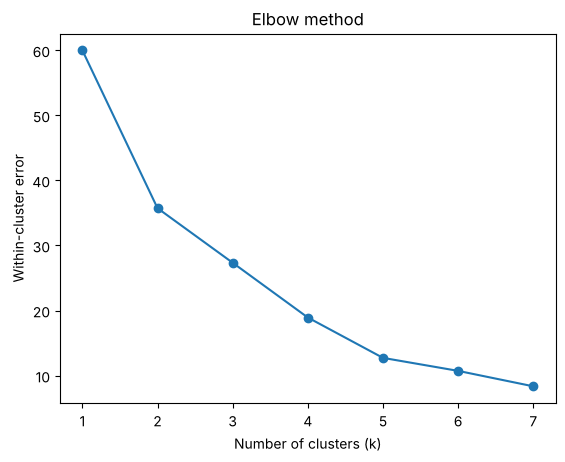

In [14]:
# Author: [Partner B]
# Scale the features so they count equally, then use the elbow method to pick k
X = StandardScaler().fit_transform(features)

errors = []
for k in range(1, 8):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(X)
    errors.append(km.inertia_)

plt.plot(range(1, 8), errors, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Within-cluster error")
plt.title("Elbow method")
plt.show()

In [15]:
# Author: [Partner B]
km = KMeans(n_clusters=4, n_init=10, random_state=42)
features["cluster"] = km.fit_predict(X)

# Average of each cluster, then list the countries in it
print(features.groupby("cluster").mean().round(2))
for c in range(4):
    print("Cluster", c, ":", list(features[features["cluster"] == c].index))

         export_share  consumption_growth  production_change
cluster                                                     
0                0.48                5.23              31.81
1                0.61                1.22               3.54
2               -0.49                3.34              37.85
3               -0.03                0.14               7.37
Cluster 0 : ['Indonesia', 'Iran', 'Iraq']
Cluster 1 : ['Algeria', 'Australia', 'Canada', 'Kazakhstan', 'Kuwait', 'Nigeria', 'Norway', 'Qatar', 'Russia', 'Saudi Arabia', 'United Arab Emirates']
Cluster 2 : ['China', 'India']
Cluster 3 : ['Brazil', 'Mexico', 'South Africa', 'United States']


In [16]:
# Author: [Partner B]
# Give each cluster a name based on its averages
def name_cluster(row):
    if row["export_share"] < 0.1 and row["consumption_growth"] > 2:
        return "Fast-growing importers"
    elif row["export_share"] < 0.1:
        return "Near-balanced producers"
    elif row["consumption_growth"] > 4:
        return "Exporters with fast-rising demand"
    else:
        return "Established exporters"

cluster_avg = features.groupby("cluster").mean()
cluster_avg["name"] = cluster_avg.apply(name_cluster, axis=1)
features["cluster_name"] = features["cluster"].map(cluster_avg["name"])
features.sort_values("cluster_name")

,export_share,consumption_growth,production_change,cluster,cluster_name
country,,,,,
Algeria,0.553561,2.367964,-3.375667,1,Established exporters
Saudi Arabia,0.559328,1.306254,-4.271005,1,Established exporters
Russia,0.431029,1.378298,6.296837,1,Established exporters
Qatar,0.765570,1.036989,1.820853,1,Established exporters
Norway,0.877653,0.208049,8.154874,1,Established exporters
Nigeria,0.634601,0.531208,-25.889814,1,Established exporters
Kuwait,0.711604,2.032179,-6.690746,1,Established exporters
United Arab Emirates,0.574716,2.113977,21.340773,1,Established exporters
Kazakhstan,0.533279,1.189131,3.923731,1,Established exporters


## 8. Supplier reliability score
Only countries that export today are scored. Each input is scaled from 0 (worst) to 1 (best):

| Weight | Input | Better when |
|---|---|---|
| 40% | Export share in 2030 (forecast) | higher |
| 30% | Consumption growth | lower |
| 20% | Production change 2015-2024 | higher |
| 10% | Production stability (std. dev. of yearly growth) | lower |

In [17]:
# Author: [Partner B]
exporters = forecast[forecast["net_exports_2024"] > 0].index

score = pd.DataFrame(index=exporters)
score["export_share_2030"] = forecast["export_share_2030"]
score["consumption_growth"] = features["consumption_growth"]
score["production_change"] = features["production_change"]
score["volatility"] = recent.groupby("country")["production_growth"].std()

def scale(column):
    return (column - column.min()) / (column.max() - column.min())

score["s_export"] = scale(score["export_share_2030"])
score["s_demand"] = 1 - scale(score["consumption_growth"])   # lower growth is better
score["s_production"] = scale(score["production_change"])
score["s_stability"] = 1 - scale(score["volatility"])        # lower volatility is better

score["score"] = 100 * (0.4 * score["s_export"] + 0.3 * score["s_demand"]
                        + 0.2 * score["s_production"] + 0.1 * score["s_stability"])
score = score.sort_values("score", ascending=False)
score[["score"]].round(1)

,score
country,
Norway,84.2
Qatar,77.0
Australia,75.3
Canada,71.7
Kazakhstan,65.8
United Arab Emirates,64.7
Kuwait,63.2
Brazil,62.6
Saudi Arabia,61.5


In [18]:
# Author: [Partner B]
# Recommendation: top third = lock in, bottom third = diversify away, rest = watch.
# Any country forecast to shrink or stop exporting is also "diversify away".
score["rank"] = range(1, len(score) + 1)
score["status"] = forecast["status"]

def recommend(row):
    if row["status"] in ["Shrinking exporter", "Becomes importer by 2040"]:
        return "Diversify away"
    elif row["rank"] <= 5:
        return "Lock in long-term"
    elif row["rank"] >= 13:
        return "Diversify away"
    else:
        return "Watch"

score["recommendation"] = score.apply(recommend, axis=1)
score[["score", "status", "recommendation"]].round(1)

,score,status,recommendation
country,,,
Norway,84.2,Stable exporter,Lock in long-term
Qatar,77.0,Stable exporter,Lock in long-term
Australia,75.3,Stable exporter,Lock in long-term
Canada,71.7,Growing exporter,Lock in long-term
Kazakhstan,65.8,Stable exporter,Lock in long-term
United Arab Emirates,64.7,Stable exporter,Watch
Kuwait,63.2,Stable exporter,Watch
Brazil,62.6,Growing exporter,Watch
Saudi Arabia,61.5,Stable exporter,Watch


In [19]:
# Author: [Partner B]
# Sensitivity check: does the ranking change much if all four inputs get equal weight?
score["score_equal"] = 25 * (score["s_export"] + score["s_demand"] + score["s_production"] + score["s_stability"])
print("Rank correlation:", round(score["score"].corr(score["score_equal"], method="spearman"), 2))

Rank correlation: 0.9


## 9. Charts for the presentation

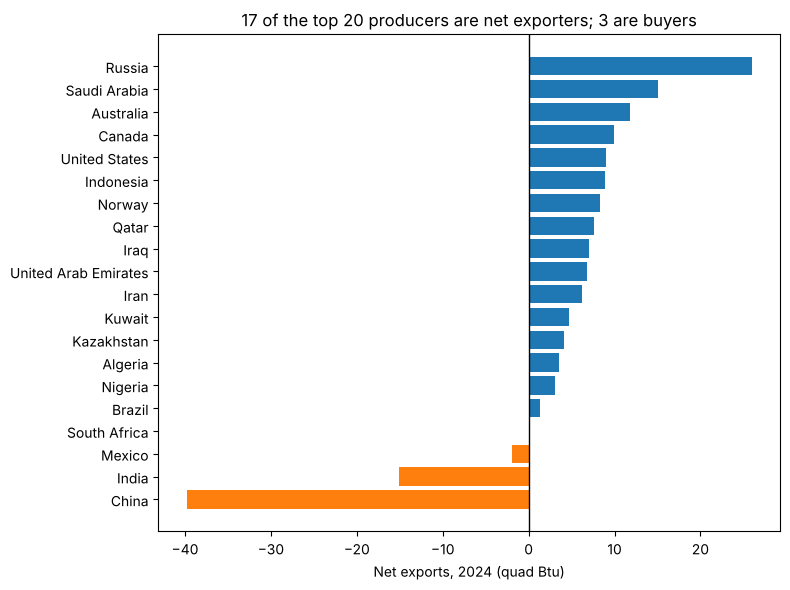

In [20]:
# Author: [Partner B]
# Chart 1: net exports in 2024
data = latest["net_exports"].sort_values()
colors = ["tab:blue" if x > 0 else "tab:orange" for x in data]

plt.figure(figsize=(8, 6))
plt.barh(data.index, data.values, color=colors)
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Net exports, 2024 (quad Btu)")
plt.title("17 of the top 20 producers are net exporters; 3 are buyers")
plt.tight_layout()
plt.savefig("figures/chart1_net_exports.png", dpi=200)
plt.show()

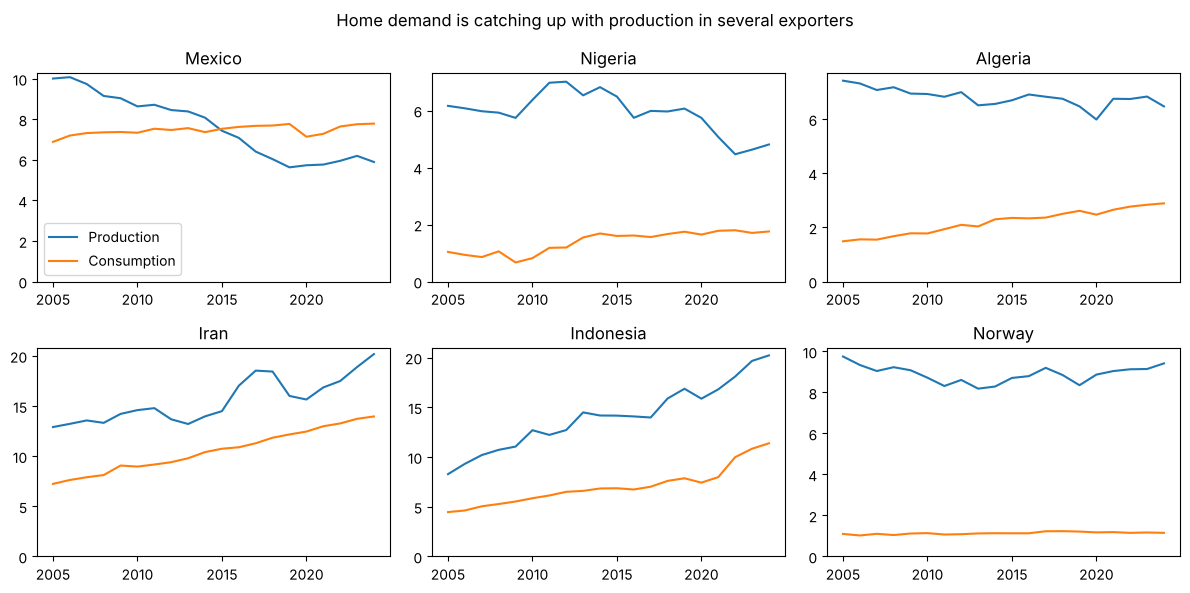

In [21]:
# Author: [Partner B]
# Chart 2: production vs consumption for six countries
countries = ["Mexico", "Nigeria", "Algeria", "Iran", "Indonesia", "Norway"]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))

for i in range(6):
    ax = axes.flat[i]
    data = df[df["country"] == countries[i]]
    ax.plot(data["year"], data["production"], label="Production")
    ax.plot(data["year"], data["consumption"], label="Consumption")
    ax.set_title(countries[i])
    ax.set_ylim(bottom=0)

axes[0, 0].legend()
fig.suptitle("Home demand is catching up with production in several exporters")
plt.tight_layout()
plt.savefig("figures/chart2_production_vs_consumption.png", dpi=200)
plt.show()

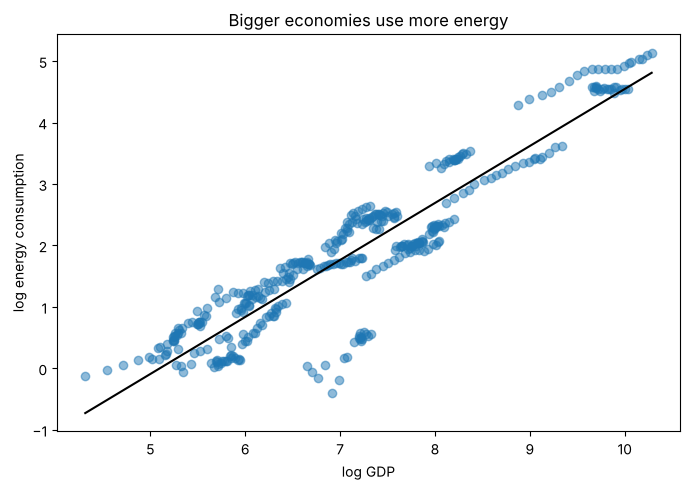

In [22]:
# Author: [Partner B]
# Chart 3: GDP vs energy consumption (log scale)
plt.figure(figsize=(7, 5))
plt.scatter(df["log_gdp"], df["log_consumption"], alpha=0.5)
slope, intercept = np.polyfit(df["log_gdp"], df["log_consumption"], 1)
x = np.linspace(df["log_gdp"].min(), df["log_gdp"].max(), 50)
plt.plot(x, slope * x + intercept, color="black")
plt.xlabel("log GDP")
plt.ylabel("log energy consumption")
plt.title("Bigger economies use more energy")
plt.tight_layout()
plt.savefig("figures/chart3_gdp_vs_consumption.png", dpi=200)
plt.show()

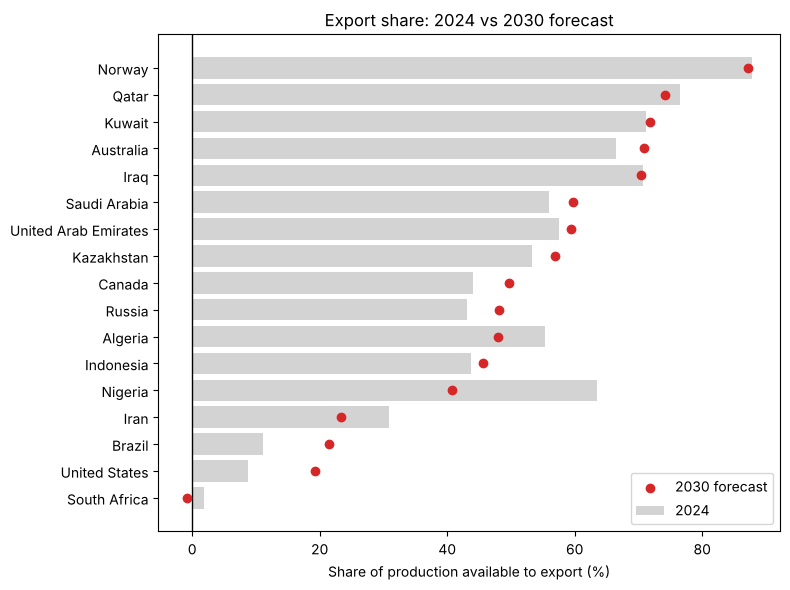

In [23]:
# Author: [Partner B]
# Chart 4: export share now vs 2030 for every exporter
data = forecast.loc[exporters].sort_values("export_share_2030")

plt.figure(figsize=(8, 6))
plt.barh(data.index, data["export_share_2024"] * 100, color="lightgray", label="2024")
plt.scatter(data["export_share_2030"] * 100, data.index, color="tab:red", zorder=3, label="2030 forecast")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Share of production available to export (%)")
plt.title("Export share: 2024 vs 2030 forecast")
plt.legend()
plt.tight_layout()
plt.savefig("figures/chart4_forecast.png", dpi=200)
plt.show()

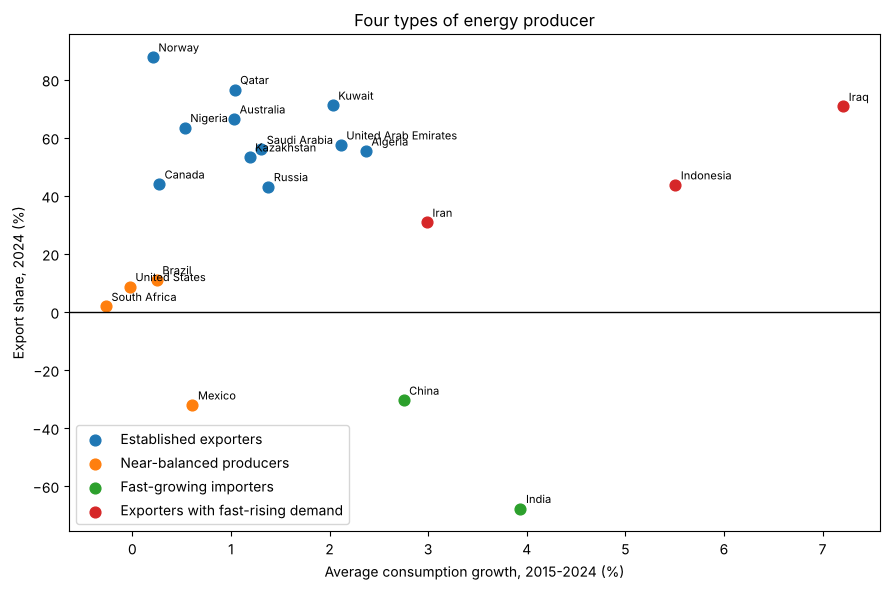

In [24]:
# Author: [Partner B]
# Chart 5: clusters
plt.figure(figsize=(9, 6))
for name in features["cluster_name"].unique():
    group = features[features["cluster_name"] == name]
    plt.scatter(group["consumption_growth"], group["export_share"] * 100, s=60, label=name)

for country in features.index:
    plt.annotate(country, (features.loc[country, "consumption_growth"], features.loc[country, "export_share"] * 100),
                 fontsize=8, xytext=(4, 4), textcoords="offset points")

plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Average consumption growth, 2015-2024 (%)")
plt.ylabel("Export share, 2024 (%)")
plt.title("Four types of energy producer")
plt.legend()
plt.tight_layout()
plt.savefig("figures/chart5_clusters.png", dpi=200)
plt.show()

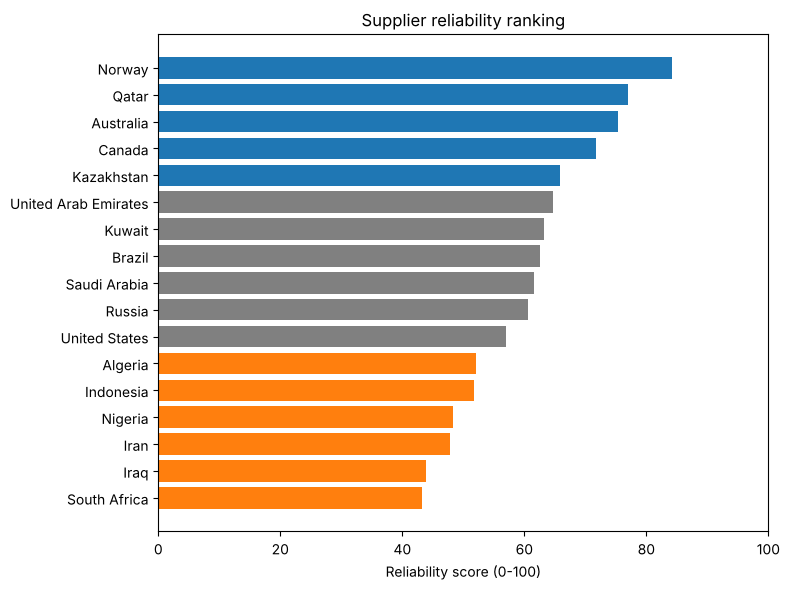

In [25]:
# Author: [Partner B]
# Chart 6: reliability ranking
data = score.sort_values("score")
color_map = {"Lock in long-term": "tab:blue", "Watch": "gray", "Diversify away": "tab:orange"}
colors = [color_map[r] for r in data["recommendation"]]

plt.figure(figsize=(8, 6))
plt.barh(data.index, data["score"], color=colors)
plt.xlabel("Reliability score (0-100)")
plt.title("Supplier reliability ranking")
plt.xlim(0, 100)
plt.tight_layout()
plt.savefig("figures/chart6_ranking.png", dpi=200)
plt.show()

## 10. Results

In [26]:
for rec in ["Lock in long-term", "Watch", "Diversify away"]:
    print(rec + ":", list(score[score["recommendation"] == rec].index))

Lock in long-term: ['Norway', 'Qatar', 'Australia', 'Canada', 'Kazakhstan']
Watch: ['United Arab Emirates', 'Kuwait', 'Brazil', 'Saudi Arabia', 'Russia', 'United States']
Diversify away: ['Algeria', 'Indonesia', 'Nigeria', 'Iran', 'Iraq', 'South Africa']


**Limitations:** straight-line forecasts; no reserves data; crude oil trade data ends in 2018 for most countries.

**Future work (MSBA 503):** add reserves and prices, use time-series forecasting models.

In [27]:
# Contribution summary (fill in before submitting)
print("[Partner A]: data cleaning, new variables, regression, forecast - __%")
print("[Partner B]: clustering, reliability score, charts - __%")

[Partner A]: data cleaning, new variables, regression, forecast - __%
[Partner B]: clustering, reliability score, charts - __%
